# Descenso de gradiente

En el módulo anterior entrenamos modelos llamando a `optimizador.step()` sin mirar qué hacía. Este notebook abre esa caja: qué es el descenso de gradiente, por qué funciona, y por qué la tasa de aprendizaje y la escala de los datos importan tanto.

**Contenido**

1. Entrenar es minimizar una función
2. La derivada indica hacia dónde moverse
3. Descenso de gradiente en una dimensión
4. La tasa de aprendizaje
5. Dos parámetros: la superficie de pérdida
6. El gradiente, a mano y con autograd
7. Descenso de gradiente sobre la superficie
8. Por qué normalizar ayuda
9. Resumen y ejercicios

In [1]:
import torch
import matplotlib.pyplot as plt

print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 1. Entrenar es minimizar una función

Un modelo tiene parámetros (en la neurona, $w$ y $b$) y una función de pérdida $L(w, b)$ que dice qué tan mal predice con esos parámetros. Los datos están fijos, así que la pérdida depende **solo de los parámetros**.

Entrenar es entonces un problema de optimización:

$$\text{encontrar } (w, b) \text{ que hagan } L(w, b) \text{ lo más pequeña posible}$$

Probar todas las combinaciones es imposible en cuanto hay más de un puñado de parámetros. El descenso de gradiente es una estrategia mucho más barata: partir en cualquier punto y **bajar paso a paso**, usando en cada paso solo información local.

## 2. La derivada indica hacia dónde moverse

Empezamos con un solo parámetro y una función sencilla:

$$f(w) = (w - 3)^2$$

Su mínimo está en $w = 3$. La derivada es $f'(w) = 2(w - 3)$, y su signo dice hacia dónde sube la función:

- Si $f'(w) > 0$, la función crece hacia la derecha. Para bajar hay que ir a la **izquierda**.
- Si $f'(w) < 0$, la función crece hacia la izquierda. Para bajar hay que ir a la **derecha**.

En ambos casos hay que moverse **en contra del signo de la derivada**. Además, la derivada es grande lejos del mínimo y pequeña cerca, así que sirve también para regular el tamaño del paso.

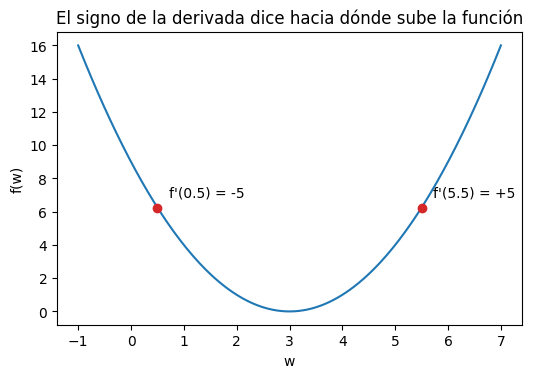

In [2]:
def f(w):
    return (w - 3) ** 2


w = torch.linspace(-1, 7, 200)

plt.figure(figsize=(6, 3.8))
plt.plot(w, f(w))
for punto in [0.5, 5.5]:
    pendiente = 2 * (punto - 3)
    plt.scatter([punto], [f(torch.tensor(punto))], color="tab:red", zorder=3)
    plt.annotate(f"f'({punto}) = {pendiente:+.0f}", (punto, f(torch.tensor(punto)).item()),
                 textcoords="offset points", xytext=(8, 8))
plt.xlabel("w")
plt.ylabel("f(w)")
plt.title("El signo de la derivada dice hacia dónde sube la función")
plt.show()

## 3. Descenso de gradiente en una dimensión

La regla de actualización resume la idea anterior en una línea:

$$w \leftarrow w - \eta \, f'(w)$$

$\eta$ (eta) es la **tasa de aprendizaje**, el `lr` de PyTorch. Se repite hasta que $w$ deja de moverse.

La implementamos con `autograd`: `backward()` calcula $f'(w)$ y lo deja en `w.grad`.

In [3]:
def descenso_1d(lr, pasos, w_inicial=0.0):
    w = torch.tensor(w_inicial, requires_grad=True)
    trayectoria = [w.item()]

    for _ in range(pasos):
        valor = f(w)
        valor.backward()                # deja f'(w) en w.grad

        with torch.no_grad():
            w -= lr * w.grad            # la regla de actualización
        w.grad.zero_()

        trayectoria.append(w.item())

    return trayectoria


trayectoria = descenso_1d(lr=0.1, pasos=25)
print("primeros valores de w:", [round(v, 3) for v in trayectoria[:6]])
print("último valor de w    :", round(trayectoria[-1], 4))

primeros valores de w: [0.0, 0.6, 1.08, 1.464, 1.771, 2.017]
último valor de w    : 2.9887


Partiendo de $w = 0$, cada paso se acerca a 3. Los pasos se van acortando solos porque la derivada se achica al acercarse al mínimo.

## 4. La tasa de aprendizaje

La tasa de aprendizaje es el hiperparámetro que más influye en el entrenamiento. Probamos tres valores sobre la misma función:

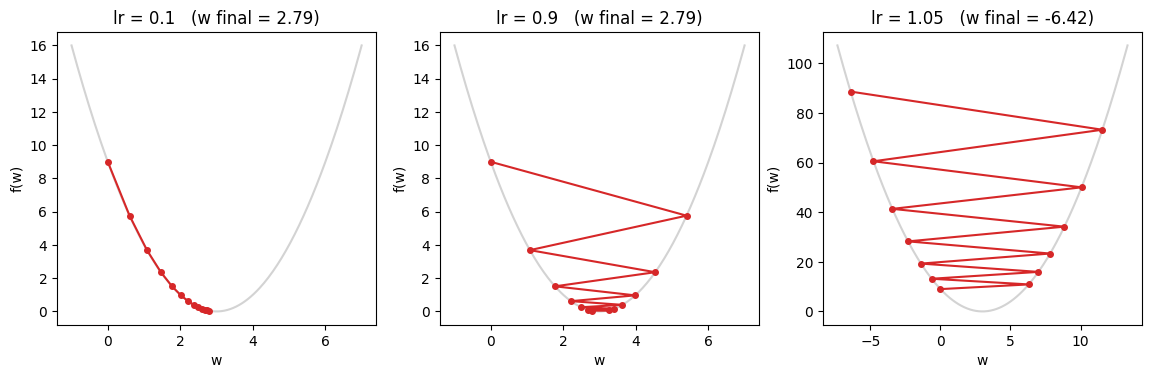

In [4]:
tasas = [0.1, 0.9, 1.05]
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))

for eje, lr in zip(ejes, tasas):
    tray = torch.tensor(descenso_1d(lr=lr, pasos=12))
    limite = max(4.0, (tray - 3).abs().max().item() * 1.1)
    w = torch.linspace(3 - limite, 3 + limite, 200)

    eje.plot(w, f(w), color="lightgray")
    eje.plot(tray, f(tray), marker="o", markersize=4, color="tab:red")
    eje.set_title(f"lr = {lr}   (w final = {tray[-1].item():.2f})")
    eje.set_xlabel("w")
    eje.set_ylabel("f(w)")

plt.show()

- **`lr = 0.1`**: baja de forma ordenada, siempre por el mismo lado.
- **`lr = 0.9`**: cada paso se pasa de largo y cae al otro lado del mínimo, pero más cerca que antes. Oscila y aun así converge.
- **`lr = 1.05`**: cada paso se pasa de largo y cae **más lejos** que antes. La pérdida crece sin control: el entrenamiento **diverge**.

En esta función se puede calcular exactamente dónde está el límite. Reemplazando $f'(w) = 2(w - 3)$ en la regla de actualización:

$$w_{k+1} - 3 = w_k - 2\eta (w_k - 3) - 3 = (1 - 2\eta)(w_k - 3)$$

El error $w_k - 3$ se multiplica por $(1 - 2\eta)$ en cada paso, y la distancia al mínimo por $|1 - 2\eta|$. Se achica solo si $|1 - 2\eta| < 1$, o sea si $0 < \eta < 1$.

| $\eta$ | Factor $1 - 2\eta$ | Comportamiento |
|---|---|---|
| 0.1 | 0.8 | se acerca sin oscilar |
| 0.5 | 0 | llega en un solo paso |
| 0.9 | −0.8 | oscila y converge |
| 1.05 | −1.1 | oscila y diverge |

El número 2 de la fórmula es la segunda derivada de $f$, es decir, su **curvatura**. En funciones cuadráticas como esta, la regla es que la tasa de aprendizaje debe ser menor que $2 / \text{curvatura}$: mientras más cerrada es la función, más pequeños deben ser los pasos. Esto vuelve a aparecer en la sección 8.

## 5. Dos parámetros: la superficie de pérdida

Volvemos a la neurona del módulo anterior, con las mismas diez entregas. Ahora hay dos parámetros, $w$ y $b$, y la pérdida es

$$L(w, b) = \frac{1}{N} \sum_{i=1}^{N} (w x_i + b - y_i)^2$$

Para cada par $(w, b)$ hay un valor de pérdida. Eso define una **superficie**, y como solo son dos parámetros la podemos dibujar completa: calculamos la pérdida en una grilla de valores y la mostramos como un mapa de curvas de nivel, igual que un mapa topográfico.

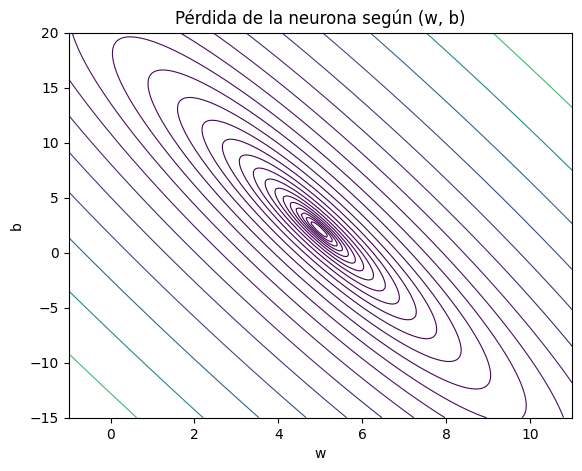

In [5]:
distancias = torch.tensor([1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5])
tiempos = torch.tensor([7.3, 9.1, 12.4, 14.2, 17.5, 19.0, 22.6, 24.1, 27.4, 29.2])


def perdida(w, b, x, y):
    return ((w * x + b - y) ** 2).mean()


def superficie(x, y, rango_w, rango_b, puntos=200):
    """Evalúa la pérdida en una grilla de valores de (w, b)."""
    ws = torch.linspace(*rango_w, puntos)
    bs = torch.linspace(*rango_b, puntos)
    W, B = torch.meshgrid(ws, bs, indexing="xy")
    # W y B tienen forma [puntos, puntos]; se agrega una dimensión para recorrer los datos
    L = ((W.unsqueeze(-1) * x + B.unsqueeze(-1) - y) ** 2).mean(dim=-1)
    return W, B, L


def dibujar_superficie(eje, W, B, L):
    niveles = torch.logspace(torch.log10(L.min()).item(), torch.log10(L.max()).item(), 25).tolist()
    eje.contour(W, B, L, levels=niveles, cmap="viridis", linewidths=0.8)
    eje.set_xlabel("w")
    eje.set_ylabel("b")


W, B, L = superficie(distancias, tiempos, rango_w=(-1, 11), rango_b=(-15, 20))

fig, eje = plt.subplots(figsize=(6.5, 5))
dibujar_superficie(eje, W, B, L)
eje.set_title("Pérdida de la neurona según (w, b)")
plt.show()

Cada curva une puntos con la misma pérdida, y el mínimo está en el centro de las curvas más pequeñas. La superficie es un **valle largo y angosto**: muy empinado en una dirección (cruzar el valle) y casi plano en la otra (recorrerlo a lo largo). Esa forma va a traer problemas.

## 6. El gradiente, a mano y con autograd

Con varios parámetros hay una derivada por cada uno. El **gradiente** es el vector que las junta:

$$\nabla L = \left( \frac{\partial L}{\partial w}, \; \frac{\partial L}{\partial b} \right)$$

Cada derivada parcial responde: "si muevo solo este parámetro un poquito, ¿cuánto cambia la pérdida?". El gradiente apunta en la dirección en que la pérdida **sube más rápido**, y es perpendicular a las curvas de nivel. Ir en la dirección contraria es la forma más rápida de bajar, al menos localmente.

Para nuestra pérdida las derivadas se obtienen con la regla de la cadena. Llamando $e_i = w x_i + b - y_i$ al error del ejemplo $i$:

$$\frac{\partial L}{\partial w} = \frac{2}{N} \sum_{i} e_i \, x_i \qquad\qquad \frac{\partial L}{\partial b} = \frac{2}{N} \sum_{i} e_i$$

Comprobamos que `autograd` entrega lo mismo que estas fórmulas:

In [6]:
w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

# Con autograd
perdida(w, b, distancias, tiempos).backward()

# Con las fórmulas
with torch.no_grad():
    error = w * distancias + b - tiempos
    dL_dw = 2 * (error * distancias).mean()
    dL_db = 2 * error.mean()

print(f"dL/dw   autograd: {w.grad.item():9.4f}   fórmula: {dL_dw.item():9.4f}")
print(f"dL/db   autograd: {b.grad.item():9.4f}   fórmula: {dL_db.item():9.4f}")

dL/dw   autograd: -114.0900   fórmula: -114.0900
dL/db   autograd:  -30.0600   fórmula:  -30.0600


Coinciden. `autograd` no usa aproximaciones numéricas de la derivada: aplica la regla de la cadena sobre las operaciones que registró, y su único error es el redondeo propio de la aritmética del computador. La ventaja es que lo hace igual de bien con dos parámetros que con millones, sin que tengas que derivar nada a mano.

Los dos valores son negativos: aumentar $w$ o $b$ desde este punto **baja** la pérdida. Y $\partial L / \partial w$ es bastante mayor en magnitud que $\partial L / \partial b$: la pérdida es mucho más sensible a $w$.

## 7. Descenso de gradiente sobre la superficie

La regla es la misma de antes, aplicada a todos los parámetros a la vez:

$$w \leftarrow w - \eta \frac{\partial L}{\partial w} \qquad\qquad b \leftarrow b - \eta \frac{\partial L}{\partial b}$$

Esto es exactamente lo que hace `torch.optim.SGD` en `step()`.

In [7]:
def descenso(x, y, lr, pasos, inicio=(0.0, 0.0)):
    """Descenso de gradiente sobre la pérdida de la neurona. Devuelve la trayectoria de (w, b)."""
    w = torch.tensor(inicio[0], requires_grad=True)
    b = torch.tensor(inicio[1], requires_grad=True)
    trayectoria = [(w.item(), b.item())]

    for _ in range(pasos):
        perdida(w, b, x, y).backward()

        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()

        trayectoria.append((w.item(), b.item()))

    return torch.tensor(trayectoria)

Lo corremos con dos tasas de aprendizaje y dibujamos el camino que sigue cada una sobre el mapa.

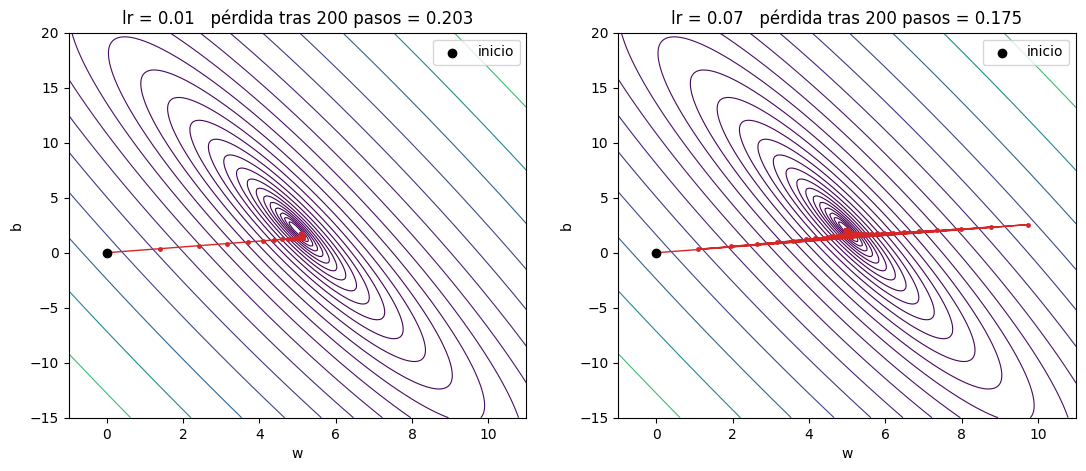

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

for eje, lr in zip(ejes, [0.01, 0.07]):
    tray = descenso(distancias, tiempos, lr=lr, pasos=200)
    final = perdida(tray[-1, 0], tray[-1, 1], distancias, tiempos).item()

    dibujar_superficie(eje, W, B, L)
    eje.plot(tray[:, 0], tray[:, 1], marker="o", markersize=2.5, linewidth=1, color="tab:red")
    eje.scatter(*tray[0], color="black", zorder=3, label="inicio")
    eje.set_title(f"lr = {lr}   pérdida tras 200 pasos = {final:.3f}")
    eje.legend()

plt.show()

Las dos trayectorias tienen dos fases:

1. **Cruzar el valle.** En pocos pasos llegan al fondo, porque en esa dirección la pendiente es fuerte. Con `lr = 0.07` lo hacen rebotando de una pared a otra.
2. **Recorrer el valle.** A lo largo del fondo la pendiente es casi nula, el gradiente es minúsculo y los pasos también. Avanzan muy lento hacia el mínimo.

El problema es que hay **una sola tasa de aprendizaje para todas las direcciones**. La dirección empinada obliga a usar una tasa pequeña (si no, diverge), y esa misma tasa resulta demasiado pequeña para la dirección plana.

Si se sube un poco más, pasa lo mismo que en la sección 4:

In [9]:
for lr in [0.07, 0.073, 0.075, 0.08]:
    tray = descenso(distancias, tiempos, lr=lr, pasos=200)
    final = perdida(tray[-1, 0], tray[-1, 1], distancias, tiempos).item()
    print(f"lr = {lr:<6}  pérdida tras 200 pasos = {final:.4g}")

lr = 0.07    pérdida tras 200 pasos = 0.1748
lr = 0.073   pérdida tras 200 pasos = 0.1753
lr = 0.075   pérdida tras 200 pasos = 1.443e+06


lr = 0.08    pérdida tras 200 pasos = 4.946e+27


Hay un umbral entre 0.073 y 0.075. Por debajo converge; por encima la pérdida explota. Ese umbral es $2 / \text{curvatura}$ en la dirección más empinada de la superficie. En `03-optimalidad` se calcula exactamente a partir de los datos.

## 8. Por qué normalizar ayuda

El valle es angosto porque los dos parámetros influyen de manera muy distinta: $w$ va multiplicado por distancias de hasta 5.5, mientras que $b$ va multiplicado por 1. Además, como todas las distancias son positivas, un cambio en $w$ se puede compensar en parte con un cambio opuesto en $b$, y eso es lo que inclina el valle.

Estandarizar la entrada (restar la media y dividir por la desviación) arregla las dos cosas. El modelo pasa a ser $\hat{y} = w \, x_{\text{norm}} + b$, y la superficie cambia de forma:

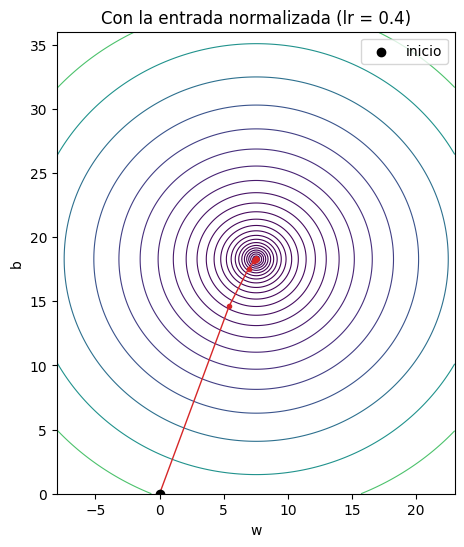

In [10]:
x_norm = (distancias - distancias.mean()) / distancias.std()

W_n, B_n, L_n = superficie(x_norm, tiempos, rango_w=(-8, 23), rango_b=(0, 36))
tray_norm = descenso(x_norm, tiempos, lr=0.4, pasos=200)

fig, eje = plt.subplots(figsize=(6, 6))
dibujar_superficie(eje, W_n, B_n, L_n)
eje.plot(tray_norm[:, 0], tray_norm[:, 1], marker="o", markersize=3, linewidth=1, color="tab:red")
eje.scatter(*tray_norm[0], color="black", zorder=3, label="inicio")
eje.set_aspect("equal")
eje.set_title("Con la entrada normalizada (lr = 0.4)")
eje.legend()
plt.show()

Las curvas de nivel ahora son casi círculos. En una superficie así el gradiente apunta prácticamente directo al mínimo, la curvatura es parecida en todas las direcciones y una misma tasa de aprendizaje sirve para todas. Se puede usar `lr = 0.4`, más de cinco veces el máximo que toleraba la versión sin normalizar.

Los valores de $w$ y $b$ son distintos a los de antes porque el modelo ahora recibe otra entrada, pero las predicciones son las mismas. Comparamos cuántos pasos necesita cada versión para quedar a menos de 0.001 de la pérdida mínima. Esa pérdida mínima se puede calcular de forma exacta con `torch.linalg.lstsq`, que resuelve el ajuste de la recta sin iterar (el porqué está en `03-optimalidad`).

In [11]:
def perdida_minima(x, y):
    A = torch.stack([x, torch.ones_like(x)], dim=1)             # columnas: x y unos
    w_opt, b_opt = torch.linalg.lstsq(A, y.unsqueeze(1)).solution.squeeze()
    return perdida(w_opt, b_opt, x, y).item()


def pasos_hasta_converger(tray, x, y, tolerancia=1e-3):
    minimo = perdida_minima(x, y)
    for paso, (w, b) in enumerate(tray):
        if perdida(w, b, x, y).item() - minimo < tolerancia:
            return paso
    return None


tray_cruda = descenso(distancias, tiempos, lr=0.07, pasos=2000)

print("Pérdida mínima posible:", round(perdida_minima(distancias, tiempos), 4))
print("Pasos sin normalizar (lr = 0.07):", pasos_hasta_converger(tray_cruda, distancias, tiempos))
print("Pasos normalizando   (lr = 0.4) :", pasos_hasta_converger(tray_norm, x_norm, tiempos))

Pérdida mínima posible: 0.1748
Pasos sin normalizar (lr = 0.07): 106
Pasos normalizando   (lr = 0.4) : 5


Mismo modelo, mismos datos, mismo algoritmo. Solo cambió la escala de la entrada y el entrenamiento se aceleró en más de un orden de magnitud. Por eso normalizar es un paso estándar al preparar datos.

## 9. Resumen

- Entrenar es **minimizar la pérdida** como función de los parámetros.
- El **gradiente** junta las derivadas parciales y apunta hacia donde la pérdida sube más rápido. El descenso de gradiente da pasos en la dirección contraria: $\theta \leftarrow \theta - \eta \nabla L$.
- `backward()` calcula el gradiente de forma exacta y `optimizador.step()` aplica esa regla.
- La **tasa de aprendizaje** decide el tamaño del paso. Muy pequeña: avanza lento. Muy grande: oscila y, pasado un umbral que depende de la curvatura, diverge.
- Cuando la superficie es un valle angosto, ninguna tasa sirve bien para todas las direcciones. **Normalizar** las entradas redondea la superficie y permite pasos más grandes.
- El gradiente es información **local**: dice hacia dónde bajar desde donde estás, sin garantizar que el punto al que llegues sea el mejor de todos. Ese es el tema de `03-optimalidad`.

En este notebook cada paso usó **todos** los datos para calcular el gradiente. Con millones de ejemplos eso es demasiado caro. El siguiente notebook muestra la solución: el descenso de gradiente estocástico.

## Ejercicios

1. En la sección 4, prueba `lr = 0.5`. ¿Cuántos pasos necesita? Explícalo con la fórmula del factor $(1 - 2\eta)$.
2. Cambia la función a $f(w) = 5 (w - 3)^2$. ¿Cuál es ahora la tasa de aprendizaje máxima? Verifícalo experimentalmente.
3. En la sección 7, parte desde `inicio=(8.0, -10.0)`. ¿Cambia el punto de llegada? ¿Cambia el camino?
4. Usa la trayectoria de la sección 7 con `lr = 0.01` y grafica la pérdida en función del paso, con escala logarítmica. Identifica las dos fases descritas.
5. En la sección 8, normaliza también los tiempos. ¿Cómo cambian los valores óptimos de $w$ y $b$? ¿Cambia la forma de la superficie?